# Graph streams: catch a burst of edges with MIDAS

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliverHennhoefer/aberrant/blob/main/examples/notebooks/02_graph_streams.ipynb)

Many streams are edges: a packet from one host to another, a payment between
accounts, a login from a device. `MIDAS` scores each edge by how far the
current count of that edge (and, in MIDAS-R, of its endpoints) departs from
its history. It keeps fixed-size count-min sketches, so memory stays constant.

Here 200 hosts talk at random. At time bucket 120, one host suddenly sends a
burst of connections to a single target.

In [ ]:
%pip install --quiet aberrant matplotlib

In [2]:
import numpy as np

rng = np.random.default_rng(3)
edges = []
for bucket in range(1, 201):
    for _ in range(40):  # background traffic
        source, target = rng.integers(0, 200, size=2)
        edges.append({"src": float(source), "dst": float(target), "t": float(bucket)})
    if 120 <= bucket <= 124:  # the attack: host 7 floods host 42
        edges.extend({"src": 7.0, "dst": 42.0, "t": float(bucket)} for _ in range(30))

print(f"{len(edges):,} edges over 200 time buckets")

8,150 edges over 200 time buckets


## Score each edge before learning it

In [3]:
from aberrant.model.graph import MIDAS

detector = MIDAS(source_key="src", destination_key="dst", time_key="t", seed=11)

scores = []
for edge in edges:
    scores.append(detector.score_one(edge))
    detector.learn_one(edge)
scores = np.array(scores)

## The burst stands out

The plot shows the highest edge score in each time bucket.

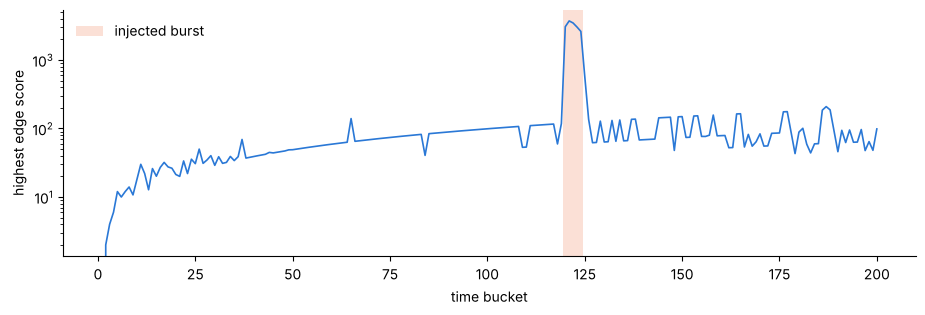

{'src': 7.0, 'dst': 42.0, 't': 121.0} score=3,712
{'src': 7.0, 'dst': 42.0, 't': 121.0} score=3,604
{'src': 7.0, 'dst': 42.0, 't': 121.0} score=3,496
{'src': 7.0, 'dst': 42.0, 't': 122.0} score=3,464
{'src': 7.0, 'dst': 42.0, 't': 121.0} score=3,388


In [4]:
import matplotlib.pyplot as plt

buckets = np.array([edge["t"] for edge in edges])
peak = np.array([scores[buckets == b].max() for b in range(1, 201)])

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(range(1, 201), peak, color="#2a78d6", linewidth=1.2)
ax.axvspan(
    119.5, 124.5, color="#eb6834", alpha=0.2, linewidth=0, label="injected burst"
)
ax.set_yscale("log")
ax.set_xlabel("time bucket")
ax.set_ylabel("highest edge score")
ax.legend(loc="upper left", frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

top = np.argsort(scores)[-5:][::-1]
for i in top:
    print(edges[i], f"score={scores[i]:,.0f}")

## Next steps

- Other graph detectors (`AnoEdgeL`, `ISCONNA`, `SignedGraphSketchDetector`) are compared in the [model guide](https://oliverhennhoefer.github.io/aberrant/user_guide/models/).
- Turn scores into alerts: [03_scores_to_alerts.ipynb](03_scores_to_alerts.ipynb).